# DistilBERT Targeted Model

Purpose of this notebook: Fine-tune one pretrained DistilBERT encoder with a three-class classification head, evaluate it on the validation split, now we are going to build an error taxonomy pretrain the DistilBert on data annoted using our error taxonomy and evaluate it on the validation split and compare it to the performance of the base model.
- Training: 2,947 sentences from the Financial PhraseBank 66% agreement subset
- Validation: 632 sentences
- Label mapping: 0 = negative, 1 = neutral, 2 = positive
- Main metric: macro-F1, because class frequencies are imbalanced



In [2]:
import sys

print(sys.executable)
from pathlib import Path
import gc
import json
import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix




c:\Users\malve\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)

Interpreter: c:\Users\malve\AppData\Local\Programs\Python\Python313\python.exe
PyTorch: 2.12.0+cpu
Device: cpu


## Data load


In [4]:


DATA_DIR = Path("Financial Phrasebank Project/data/splits")

train_df = pd.read_csv(DATA_DIR / "train.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")

# Keep a stable identifier for joining annotations back to training rows.
train_df = train_df.reset_index(drop=True).copy()
train_df["row_id"] = range(len(train_df))

annotation_columns = [
    "has_negation",
    "has_mixed_sentiment",
    "has_expectation_comparison",
     "has_financial_terminology",
    "annotation_notes",
]



annotations = pd.read_excel(
    "train_phenomena_annotations.xlsx",
    sheet_name="Annotations"
)



train_texts = set(train_df["sentence_clean"].astype(str))

annotations["sentence_clean"] = (
    annotations["sentence_clean"].astype(str)
)

annotations["in_training_split"] = (
    annotations["sentence_clean"].isin(train_texts)
)

print("Reviewed sentences:", len(annotations))
print(
    "Sentences matching training split:",
    annotations["in_training_split"].sum()
)
print(
    "Sentences outside training split:",
    (~annotations["in_training_split"]).sum()
)

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Annotation rows:", len(annotations))

print("\nAnnotation columns:")
print(annotations.columns.tolist())
annotations = annotations.drop(columns=["has_financial_terminology"])
annotations.head()




Reviewed sentences: 200
Sentences matching training split: 140
Sentences outside training split: 60
Training rows: 2947
Validation rows: 632
Annotation rows: 200

Annotation columns:
['row_id', 'sentence', 'sentence_clean', 'label', 'has_negation', 'has_mixed_sentiment', 'has_expectation_comparison', 'has_financial_terminology', 'has_implicit_sentiment', 'annotation_notes', 'review_status', 'suggestion_basis', 'in_training_split']


,row_id,sentence,sentence_clean,label,has_negation,has_mixed_sentiment,has_expectation_comparison,has_implicit_sentiment,annotation_notes,review_status,suggestion_basis,in_training_split
0,0,"According to Gran , the company has no plans t...","According to Gran , the company has no plans t...",1,1,0,0,1,NaN,Review suggested labels,Keyword/rule-based suggestion; verify sentence...,True
1,1,Technopolis plans to develop in stages an area...,Technopolis plans to develop in stages an area...,1,1,0,0,1,NaN,Review suggested labels,Keyword/rule-based suggestion; verify sentence...,True
2,13,Consolidated net sales increased 16 % to reach...,Consolidated net sales increased 16 % to reach...,2,0,1,1,1,NaN,Review suggested labels,Keyword/rule-based suggestion; verify sentence...,True
3,53,Sales for the Department Store Division increa...,Sales for the Department Store Division increa...,2,0,1,0,0,NaN,Review suggested labels,Keyword/rule-based suggestion; verify sentence...,True
4,73,No blind-spots coming from 1 vantage point all...,No blind-spots coming from 1 vantage point all...,1,1,0,0,0,NaN,Review suggested labels,Keyword/rule-based suggestion; verify sentence...,True


In [5]:
taxonomy_columns = [
    "has_negation",
    "has_mixed_sentiment",
    "has_expectation_comparison",
    "has_implicit_sentiment",
]

required = ["sentence_clean", "label", *taxonomy_columns]
missing = [column for column in required if column not in annotations.columns]
if missing:
    raise ValueError(f"Missing required annotation columns: {missing}")

# Ensure labels in annotation columns are numeric 0/1.
for column in taxonomy_columns:
    annotations[column] = pd.to_numeric(annotations[column], errors="coerce")
    invalid = annotations[column].isna() | ~annotations[column].isin([0, 1])
    if invalid.any():
        bad_rows = annotations.index[invalid].tolist()[:10]
        raise ValueError(
            f"{column} has blank/invalid values at annotation rows {bad_rows}. "
            "Fill each phenomenon column with 0 or 1 before training."
        )

# Match on cleaned sentence AND sentiment label.
def make_key(frame):
    return list(zip(
        frame["sentence_clean"].fillna("").astype(str),
        frame["label"].astype(str)
    ))

train_keys = set(make_key(train_df))
validation_keys = set(make_key(validation_df))
annotations["_key"] = make_key(annotations)
annotations["in_train"] = annotations["_key"].isin(train_keys)
annotations["in_validation"] = annotations["_key"].isin(validation_keys)

print("Total reviewed rows:", len(annotations))
print("Matching training data:", int(annotations["in_train"].sum()))
print("Matching validation data:", int(annotations["in_validation"].sum()))
print("Matching neither:", int((~annotations["in_train"] & ~annotations["in_validation"]).sum()))

# Only rows matched exclusively to training are allowed to guide sampling.
train_annotations = annotations.loc[
    annotations["in_train"] & ~annotations["in_validation"]
].copy()
validation_annotations = annotations.loc[annotations["in_validation"]].copy()

train_annotations["is_targeted"] = (
    train_annotations[taxonomy_columns].sum(axis=1) > 0
)

print("Training annotations used:", len(train_annotations))
print("Annotated targeted rows:", int(train_annotations["is_targeted"].sum()))
print("Validation annotations held out for evaluation only:", len(validation_annotations))
print("\nTraining examples per phenomenon:")
print(train_annotations[taxonomy_columns].sum())

# add a target flag aligned to train_df's row order.
# Unannotated training rows keep is_targeted=False and receive ordinary sampling weight.
targeted_keys = set(
    train_annotations.loc[train_annotations["is_targeted"], "_key"]
)
train_df["_key"] = make_key(train_df)
train_df["is_targeted"] = train_df["_key"].isin(targeted_keys)

print("\nTraining rows marked targeted:", int(train_df["is_targeted"].sum()))
print("Unannotated / non-targeted rows:", int((~train_df["is_targeted"]).sum()))



Total reviewed rows: 200
Matching training data: 140
Matching validation data: 23
Matching neither: 37
Training annotations used: 140
Annotated targeted rows: 112
Validation annotations held out for evaluation only: 23

Training examples per phenomenon:
has_negation                  35
has_mixed_sentiment           19
has_expectation_comparison    44
has_implicit_sentiment        43
dtype: int64

Training rows marked targeted: 112
Unannotated / non-targeted rows: 2835


In [6]:
RANDOM_STATE= 42
LABELS= {0: "negative", 1: "neutral", 2: "positive"}
CLASS_ORDER= [0,1,2]
expected_col= {"sentence", "sentence_clean", "label"}
LABEL2ID = {name: i for i, name in LABELS.items()}
for split_name, frame in [("train", train_df), ("validation", validation_df)]:
    assert expected_col.issubset(frame.columns), f"Missing columns in {split_name}"
    assert frame[list(expected_col)].notna().all().all(), f"Missing values in {split_name}"
    assert set(frame["label"].unique()) == set(CLASS_ORDER), f"Unexpected labels in {split_name}"
    assert not frame["sentence_clean"].duplicated().any(), f"Duplicates in {split_name}"
    
    assert len(train_df) == 2947 and len(validation_df) == 632, "Unexpected split size — verify repository branch"
    summary = pd.DataFrame({
    "train_count": train_df["label"].value_counts().reindex(CLASS_ORDER),
    "validation_count": validation_df["label"].value_counts().reindex(CLASS_ORDER).reindex(CLASS_ORDER),
})
summary.index = [LABELS[i] for i in CLASS_ORDER]
summary

,train_count,validation_count
negative,360,77
neutral,1770,379
positive,817,176


## 4. DistilBERT tokenization
DistilBERT breaks the text into subword tokens and generates input_ids plus an attention_mask. A fixed maximum length lets us batch sentences efficiently.

Important: from_pretrained loads the tokenizer's existing vocabulary; it does not learn a new vocabulary from our validation set

In [7]:
X_train = train_df["sentence"].astype(str).tolist()
X_validation = validation_df["sentence"].astype(str).tolist()
y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = validation_df["label"].to_numpy(dtype=np.int64)

In [8]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(X_train, truncation=True, padding="max_length",max_length=MAX_LENGTH, return_tensors="pt")
val_encodings = tokenizer( X_validation, truncation=True, padding="max_length",max_length=MAX_LENGTH, return_tensors="pt")

train_lengths = [len(ids) for ids in tokenizer(X_train, truncation=False)["input_ids"]]
truncated = sum(length > MAX_LENGTH for length in train_lengths)
print("Training sequences above MAX_LENGTH:", truncated, "of", len(train_lengths))
print("Training input IDs:", tuple(train_encodings["input_ids"].shape))
print("Validation input IDs:", tuple(val_encodings["input_ids"].shape))
print("Example tokens:", tokenizer.tokenize(X_train[0])[:35])

Training sequences above MAX_LENGTH: 1 of 2947
Training input IDs: (2947, 128)
Validation input IDs: (632, 128)
Example tokens: ['the', 'biggest', 'sellers', 'in', 'the', 'chain', "'", 's', 'supermarkets', 'in', 'finland', 'are', 'organic', 'pi', '##rk', '##ka', 'tomatoes', ',', 'carrot', '##s', ',', 'eggs', ',', 'and', 'meat', 'products', '.']


### Model



In [9]:

train_dataset = [
    {"input_ids": train_encodings["input_ids"][i],"attention_mask": train_encodings["attention_mask"][i], "labels": torch.tensor(y_train[i], dtype=torch.long)}
    for i in range(len(y_train))]


val_dataset = [
    {"input_ids": val_encodings["input_ids"][i],"attention_mask": val_encodings["attention_mask"][i], "labels": torch.tensor(y_val[i], dtype=torch.long)} for i in range(len(y_val))]

train_loader = DataLoader(train_dataset,batch_size=16,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=16,shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 185
Validation batches: 40


# Targeted Random Sampling


In [10]:
# Weighted sampling: targeted rows are drawn more frequently, but all original
# training examples remain available. This does NOT change sentiment labels.
from torch.utils.data import WeightedRandomSampler

TARGET_WEIGHT = 5.0  # made the weight really big because targetted sample is small; compare with baseline
sample_weights = np.where(
    train_df["is_targeted"].to_numpy(dtype=bool),
    TARGET_WEIGHT,
    1.0,
)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(RANDOM_STATE)

targeted_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True,
    generator=sampler_generator,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=targeted_sampler,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Targeted weight:", TARGET_WEIGHT)

Training dataset: 2947
Validation dataset: 632
Training batches: 185
Validation batches: 40
Targeted weight: 5.0


In [11]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=LABELS,
    label2id=LABEL2ID,
)
model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print("Trainable model parameters:", f"{n_params:,}")
print("Labels:", model.config.id2label)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 504.27it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable model parameters: 66,955,779
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


In [12]:
lr = 2e-5
weight_decay = 0.01
EPOCHS = 3
PATIENCE = 2

output_dir = Path("results/distilbert_targeted")
model_dir = output_dir / "best_model_maybe"
output_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=lr, weight_decay=weight_decay
)

@torch.no_grad()
def evaluate_model(current_model, loader):
    current_model.eval()
    all_true= []
    all_pred= []
    all_probs=[]
    total_loss = 0.0
    total_n = 0

    for batch in loader:
        batch = {name: tensor.to(device) for name, tensor in batch.items()}
        outputs = current_model(**batch)
        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        batch_n = batch["labels"].size(0)
        total_loss += outputs.loss.item() * batch_n
        total_n += batch_n
        all_true.extend(batch["labels"].cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())
        all_probs.append(probabilities.cpu().numpy())

    return {
        "loss": total_loss / total_n,
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(all_true, all_pred, average="macro", labels=CLASS_ORDER, zero_division=0),
        "true": np.asarray(all_true),
        "pred": np.asarray(all_pred),
        "probabilities": np.vstack(all_probs),
    }


## Optimization of epochs and batches

In [13]:
history= []
best_f1= -1.0
best_epoch= None
no_improvement= 0

for epoch in range(1, EPOCHS + 1):
    start= time.perf_counter()
    model.train()
    total_train_loss = 0.0
    total_train_examples = 0

    for step, batch in enumerate(train_loader, start=1):
        batch= {name: tensor.to(device) for name, tensor in batch.items()}
        optimizer.zero_grad()

        outputs= model(**batch)
        loss= outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        batch_n= batch["labels"].size(0)
        total_train_loss+= loss.item() * batch_n
        total_train_examples+= batch_n

        if step % 50== 0 or step== len(train_loader):
            print(f"Epoch {epoch}/{EPOCHS} - batch {step}/{len(train_loader)}")

    train_loss= total_train_loss / total_train_examples
    val_metrics= evaluate_model(model, val_loader)
    epoch_seconds= time.perf_counter() - start

    history.append({"epoch": epoch,"train_loss": train_loss, "val_loss": val_metrics["loss"],"val_accuracy": val_metrics["accuracy"],"val_macro_f1": val_metrics["macro_f1"],"seconds": epoch_seconds, })

    print(
        f"Epoch {epoch}: train loss={train_loss:.4f}, " f"val loss={val_metrics['loss']:.4f}, "f"val accuracy={val_metrics['accuracy']:.4f}, " f"va macro-F1={val_metrics['macro_f1']:.4f}, " f"time={epoch_seconds:.1f}s")

    if val_metrics["macro_f1"] > best_f1 + 1e-4:
        best_f1= val_metrics["macro_f1"]
        best_epoch= epoch
        no_improvement= 0
        model.save_pretrained(model_dir)
        tokenizer.save_pretrained(model_dir)
        print("  Saved improved checkpoint.")
    else:
        no_improvement+= 1
        if no_improvement>= PATIENCE:
            print("Stopping early: validation macro-F1 did not improve.")
            break

history_df = pd.DataFrame(history)
#display(history_df)
print(f"Best epoch: {best_epoch} | best validation macro-F1: {best_f1:.4f}")

Epoch 1/3 - batch 50/185
Epoch 1/3 - batch 100/185
Epoch 1/3 - batch 150/185
Epoch 1/3 - batch 185/185
Epoch 1: train loss=0.5734, val loss=0.3858, val accuracy=0.8544, va macro-F1=0.8245, time=1088.6s


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.60it/s]


  Saved improved checkpoint.
Epoch 2/3 - batch 50/185
Epoch 2/3 - batch 100/185
Epoch 2/3 - batch 150/185
Epoch 2/3 - batch 185/185
Epoch 2: train loss=0.2157, val loss=0.3913, val accuracy=0.8718, va macro-F1=0.8403, time=1191.8s


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.63it/s]


  Saved improved checkpoint.
Epoch 3/3 - batch 50/185
Epoch 3/3 - batch 100/185
Epoch 3/3 - batch 150/185
Epoch 3/3 - batch 185/185
Epoch 3: train loss=0.1627, val loss=0.4231, val accuracy=0.8734, va macro-F1=0.8431, time=1109.0s


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.21it/s]

  Saved improved checkpoint.
Best epoch: 3 | best validation macro-F1: 0.8431


## Validation and test 


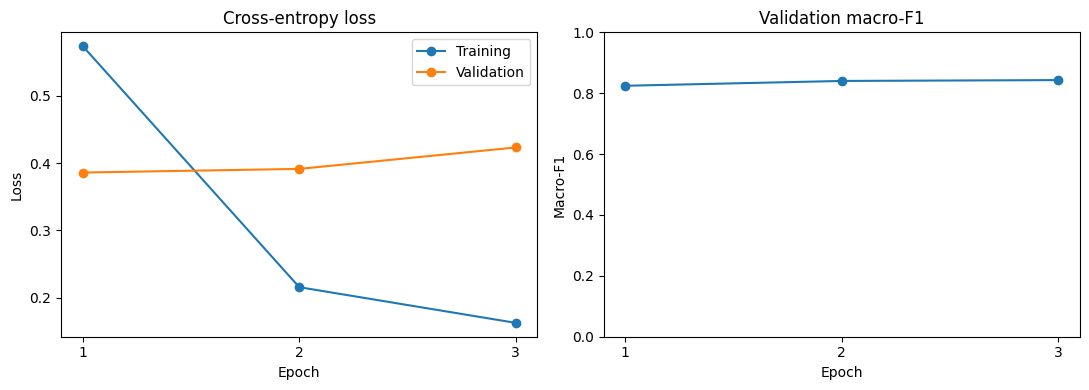

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], marker="o")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))
for ax in axes:
    ax.set_xticks(history_df["epoch"])
plt.tight_layout()
plt.show()

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 802.70it/s]


Validation accuracy: 0.8734
Validation macro-F1: 0.8431

Classification report:
              precision    recall  f1-score   support

    negative      0.720     0.870     0.788        77
     neutral      0.915     0.910     0.913       379
    positive      0.864     0.795     0.828       176

    accuracy                          0.873       632
   macro avg      0.833     0.859     0.843       632
weighted avg      0.877     0.873     0.874       632



,Predicted negative,Predicted neutral,Predicted positive
Actual negative,67,8,2
Actual neutral,14,345,20
Actual positive,12,24,140


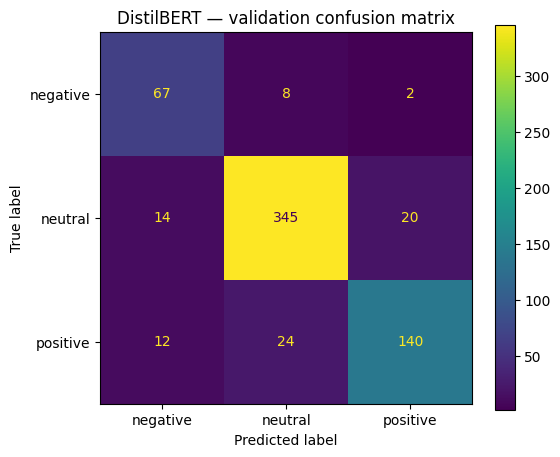

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = AutoModelForSequenceClassification.from_pretrained(model_dir)
best_model.to(device)

val_results = evaluate_model(best_model, val_loader)
y_pred = val_results["pred"]

print(f"Validation accuracy: {val_results['accuracy']:.4f}")
print(f"Validation macro-F1: {val_results['macro_f1']:.4f}")
print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=CLASS_ORDER,
    target_names=[LABELS[i] for i in CLASS_ORDER],
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(y_val, y_pred, labels=CLASS_ORDER)
display(pd.DataFrame(
    cm,
    index=["Actual " + LABELS[i] for i in CLASS_ORDER],
    columns=["Predicted " + LABELS[i] for i in CLASS_ORDER],
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[LABELS[i] for i in CLASS_ORDER]).plot(ax=ax)
ax.set_title("DistilBERT — validation confusion matrix")
plt.show()

In [ ]:
predictions_df = validation_df[["sentence", "label"]].copy().reset_index(drop=True)
predictions_df["true_sentiment"] = predictions_df["label"].map(LABELS)
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_sentiment"] = predictions_df["predicted_label"].map(LABELS)
predictions_df["correct"] = predictions_df["label"] == predictions_df["predicted_label"]

for i, name in LABELS.items():
    predictions_df[f"prob_{name}"] = val_results["probabilities"][:, i]
predictions_df["confidence"] = val_results["probabilities"].max(axis=1)

errors_df = predictions_df.loc[~predictions_df["correct"]].copy()

print("Misclassified validation sentences:", len(errors_df))
display(errors_df[["sentence", "true_sentiment", "predicted_sentiment", "confidence"]].head(20))

Misclassified validation sentences: 80


,sentence
4,"Compared with the FTSE 100 index , which rose ..."
10,"The tower it chose to add , due to go into ope..."
14,The prosecutor is also demanding Outokumpu pay...
19,"`` Soon after , the collisions started . ''"
51,It expects revenue between $ 8.4 billion and $...
64,"For Q2 2010 , consolidated earnings before tax..."
65,"Beef imports fell slightly from 2006 , to 14mn..."
69,The sale of the Healthcare Trade business supp...
70,Finnish metal products company Componenta Oyj ...
73,"According to Bosse , the present cooperation i..."


In [22]:
errors = errors_df[["sentence"]].tolist()

AttributeError: 'DataFrame' object has no attribute 'tolist'